# 🎙️ Deepfake Voice Recognition Using Convolutional Neural Networks (CNN)

## 📌 Problem Statement
With the rapid advancements in generative AI and neural audio synthesis, cloning human voices has become increasingly accessible. This poses significant security, privacy, and authenticity risks, making automated deepfake voice detection a critical capability. 

The objective of this project is to build an end-to-end deep learning pipeline using a **Convolutional Neural Network (CNN)** to accurately distinguish between **Real** human speech and **Fake** (AI-synthesized/cloned) voice recordings.

---

## ⚙️ Project Pipeline & Steps

1. **Exploratory Data Analysis & Audio Visualization**
   * Loading raw audio tracks and inspecting class distributions.
   * Visualizing waveforms, Spectrograms, Mel-Spectrograms, Chromagrams, and Mel-Frequency Cepstral Coefficients (MFCCs) to understand acoustic differences.
2. **Feature Extraction & Preprocessing**
   * Extracting 40-dimensional MFCC features from audio files using [Librosa](https://librosa.org/).
   * Standardizing temporal length via padding/trimming and applying feature normalization.
3. **Handling Class Imbalance**
   * Using **Random Oversampling** to resolve class skew between real and fake audio samples.
4. **Model Architecture & Training**
   * Constructing a 2D CNN with convolutional layers, max pooling, dropout regularizations, and a sigmoid classification head.
   * Utilizing callbacks like `EarlyStopping` and `ReduceLROnPlateau` for stable training convergence.
5. **Evaluation & Deployment Readiness**
   * Generating Confusion Matrices and Classification Reports to measure precision, recall, and F1-scores.
   * Exporting the trained model architecture to `.keras` format for web integration.

# 1. Exploratory Data Analysis & Audio Visualization

### 1.1 Importing Important Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
import librosa
from tqdm.notebook import tqdm
import IPython

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report
from imblearn.over_sampling import RandomOverSampler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation,Reshape,MaxPooling2D, Dropout, Conv2D, MaxPool2D, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

### 1.2 Loading the data and initial exploration

**steps involved in this section:**
- Loading the dataset
- checking the length of available audio paths and labels
- No. of real and fake audio present

In [4]:
import os

paths = []
labels = []

# Define the root directory
root_dir = '/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO'

# Iterate through the subdirectories
for subdir in os.listdir(root_dir):
    subdir_path = os.path.join(root_dir, subdir)
    # Check if it's a directory
    if os.path.isdir(subdir_path):
        # Add all files in the subdirectory
        for filename in os.listdir(subdir_path):
            file_path = os.path.join(subdir_path, filename)
            paths.append(file_path)
            # Add label based on the subdirectory name
            labels.append(subdir)

print('Dataset is loaded')


Dataset is loaded


In [5]:
# Checking length of available audio files
len(paths)

64

In [6]:
# printing first five audio files path
paths[:5]

['/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO/FAKE/trump-to-Obama.wav',
 '/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO/FAKE/margot-to-musk.wav',
 '/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO/FAKE/linus-to-obama.wav',
 '/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO/FAKE/taylor-to-trump.wav',
 '/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO/FAKE/taylor-to-biden.wav']

In [7]:
len(labels)

64

In [8]:
df = pd.DataFrame()
df['speech'] = paths
df['label'] = labels

In [9]:
df['label'].value_counts()

label
FAKE    56
REAL     8
Name: count, dtype: int64

In [10]:
audio_path = '/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO'
real_audio_path = 'REAL'
fake_audio_path = 'FAKE'

In [11]:
folders = os.listdir(audio_path)
print(folders)

['FAKE', 'REAL']


In [12]:
real_audio = '/kaggle/input/deep-voice-deepfake-voice-recognition/DEMONSTRATION/DEMONSTRATION/linus-original-DEMO.mp3'
fake_audio = '/kaggle/input/deep-voice-deepfake-voice-recognition/DEMONSTRATION/DEMONSTRATION/linus-to-musk-DEMO.mp3'

---

### 📊 1.3 Audio Visualization

To help our Convolutional Neural Network "see" sound, we convert 1D raw audio waveforms into 2D visual representations. Below is an overview of the core audio analysis library and feature plots used in this project:

#### 🛠️ Librosa Overview
[Librosa](https://librosa.org/) is the foundational Python library used here for music and audio processing. It handles tasks such as loading audio files into numerical arrays, resampling sample rates, and transforming time-series signals into mathematical representations that machine learning models can process.

---

#### 📈 Audio Visualizations Explained

**1. Waveform**
  * **What it shows:** A direct plot of audio amplitude (volume) over time. 
  * **Use case:** Helpful for spotting clipping, silent regions, and the overall duration or rhythm of a voice clip.

**2. Spectrogram (STFT)**
  * **What it shows:** Generated using the Short-Time Fourier Transform (STFT), this breaks audio into overlapping time windows to display **Time** (x-axis), **Frequency** (y-axis), and **Amplitude** (color intensity).
  * **Use case:** Lets the model observe frequency shifts and harmonic structures across time.

**3. Mel-Spectrogram**
  * **What it shows:** A spectrogram where the frequency axis is converted to the **Mel scale**—a logarithmic scale that mimics how the human ear naturally perceives pitch (giving more resolution to lower frequencies).
  * **Use case:** Aligns acoustic data closer to human perception, making it easier for CNN filters to learn meaningful auditory patterns.

**4. Chromagram**
  * **What it shows:** Maps the audio spectrum across the **12 distinct pitch classes** (C, C#, D, up to B), collapsing all octaves into a single octave.
  * **Use case:** Captures harmonic and tonal textures, which helps the model understand pitch changes and tonal properties in speech.

**5. Mel-Frequency Cepstral Coefficients (MFCCs)**
  * **What it shows:** Compact representations of the short-term power spectrum derived by taking the log of the Mel-spectrogram and applying a Discrete Cosine Transform (DCT).
  * **Use case:** **The industry standard for speech recognition.** They isolate the shape of the vocal tract while filtering out minor noise, serving as the primary 2D matrix fed directly into our CNN layers.

In [13]:
print('Real Audio:')
IPython.display.Audio(real_audio)

Real Audio:


In [14]:
print('Fake Audio:')
IPython.display.Audio(fake_audio)


Fake Audio:


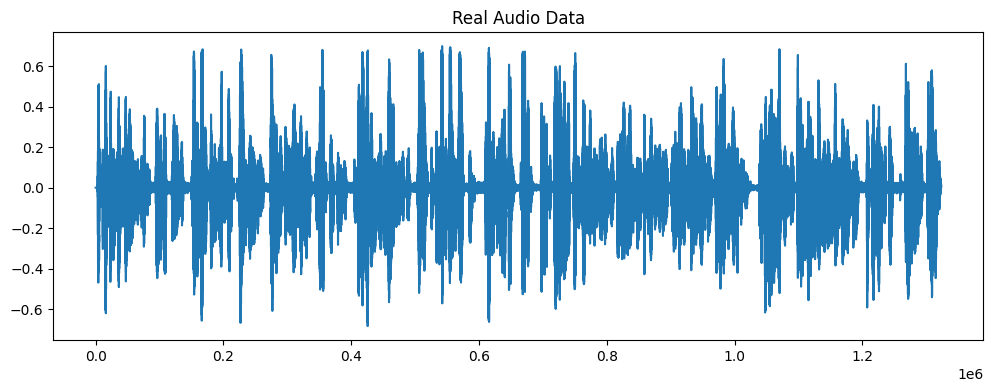

In [15]:
real_ad, real_sr = librosa.load(real_audio)
plt.figure(figsize= (12,4))
plt.plot(real_ad)
plt.title('Real Audio Data')
plt.show()

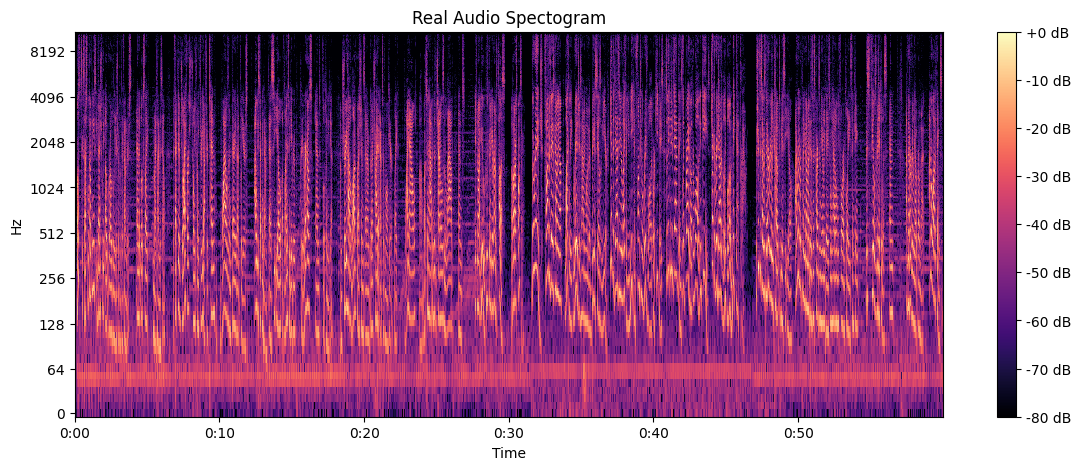

In [16]:
real_spec = np.abs(librosa.stft(real_ad))
real_spec = librosa.amplitude_to_db(real_spec, ref = np.max)
plt.figure(figsize=(14,5))
librosa.display.specshow(real_spec, sr = real_sr, x_axis = 'time', y_axis = 'log')
plt.colorbar(format = '%+2.0f dB')
plt.title("Real Audio Spectogram")
plt.show()

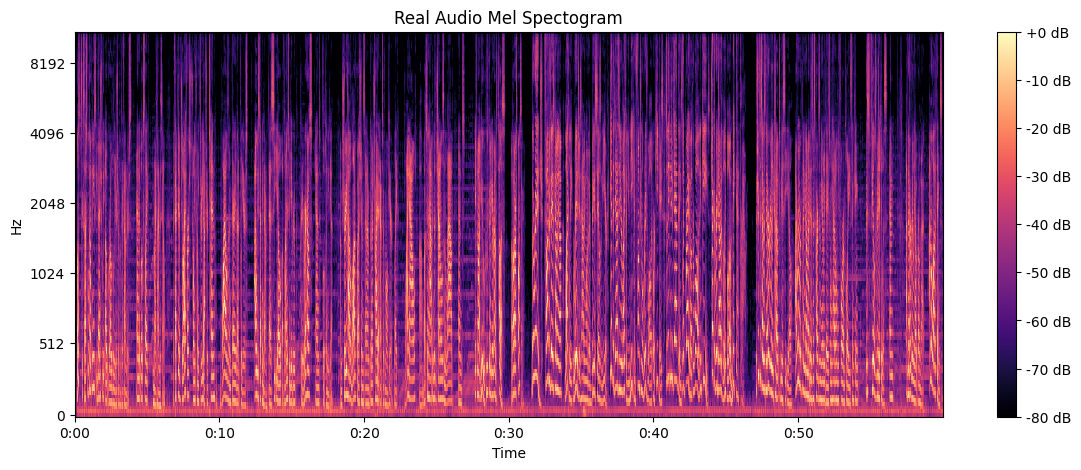

In [17]:
real_mel_spect = librosa.feature.melspectrogram(y = real_ad, sr = real_sr)
real_mel_spect = librosa.power_to_db(real_mel_spect, ref = np.max)
plt.figure(figsize = (14,5))
librosa.display.specshow(real_mel_spect, y_axis ='mel', x_axis = 'time')
plt.title('Real Audio Mel Spectogram')
plt.colorbar(format = '%+2.0f dB')
plt.show()

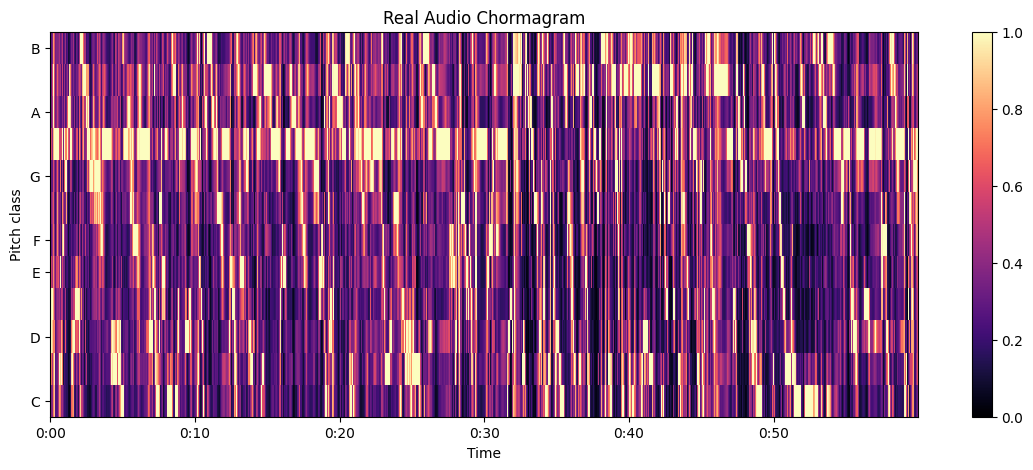

In [18]:
real_chroma = librosa.feature.chroma_cqt(y = real_ad, sr = real_sr, bins_per_octave=36)
plt.figure(figsize = (14, 5))
librosa.display.specshow(real_chroma, sr = real_sr, x_axis = 'time', y_axis = 'chroma', vmin = 0, vmax = 1)
plt.colorbar()
plt.title('Real Audio Chormagram')
plt.show()

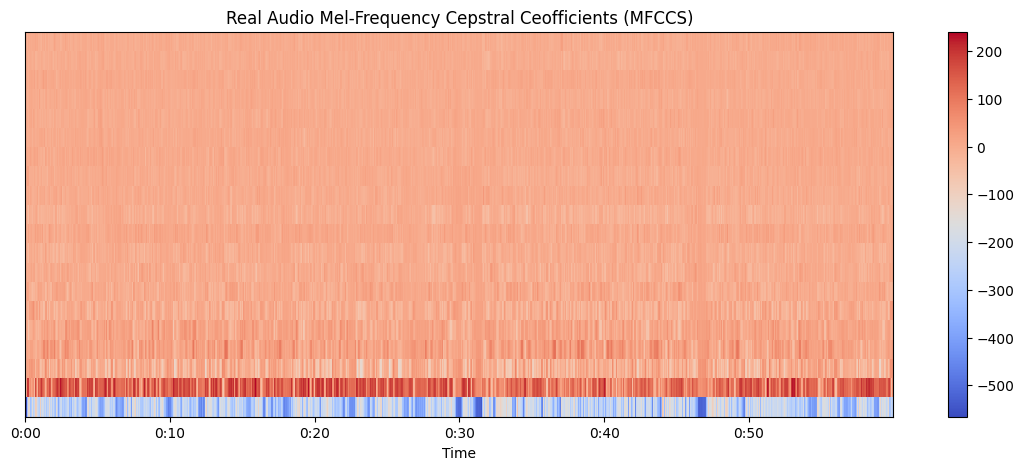

In [19]:
real_mfcc = librosa.feature.mfcc(y = real_ad, sr = real_sr)
plt.figure(figsize = (14,5))
librosa.display.specshow(real_mfcc, sr = real_sr, x_axis ='time')
plt.colorbar()
plt.title('Real Audio Mel-Frequency Cepstral Ceofficients (MFCCS)')
plt.show()

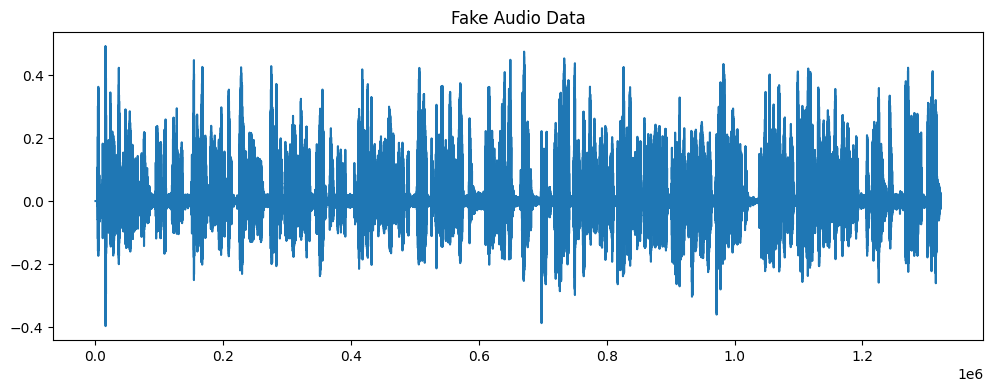

In [20]:
fake_ad, fake_sr = librosa.load(fake_audio)
plt.figure(figsize =(12,4))
plt.plot(fake_ad)
plt.title("Fake Audio Data")
plt.show()

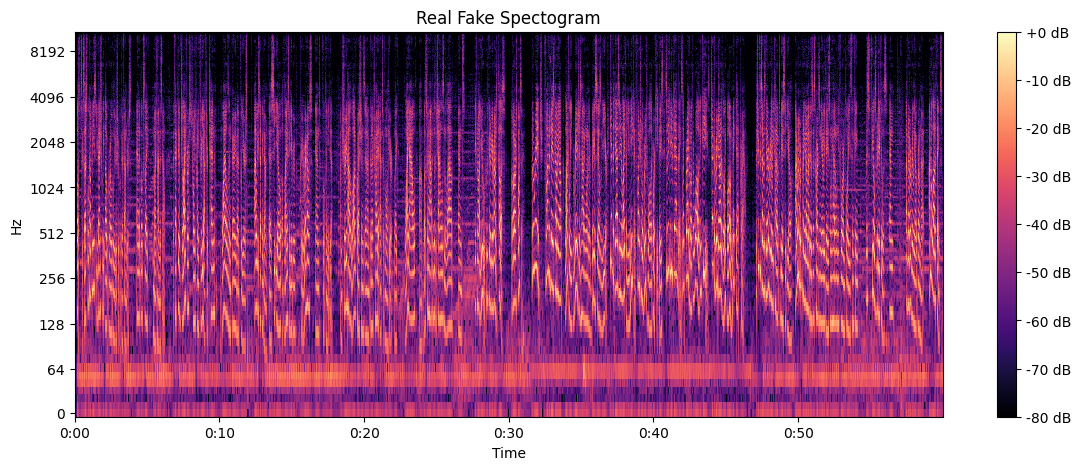

In [21]:
fake_spec = np.abs(librosa.stft(fake_ad))
fake_spec = librosa.amplitude_to_db(fake_spec, ref = np.max)
plt.figure(figsize=(14,5))
librosa.display.specshow(fake_spec, sr = fake_sr, x_axis = 'time', y_axis = 'log')
plt.colorbar(format = '%+2.0f dB')
plt.title("Real Fake Spectogram")
plt.show()

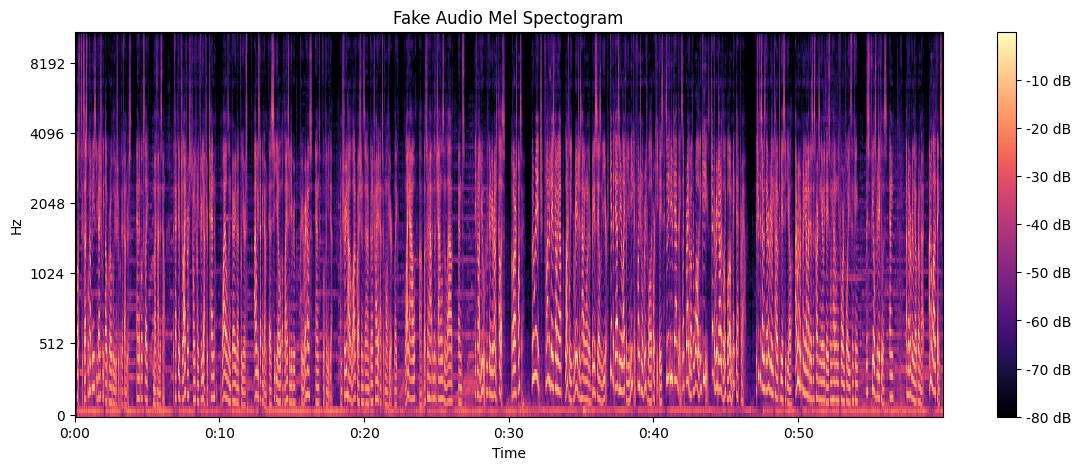

In [22]:
fake_mel_spect = librosa.feature.melspectrogram(y = fake_ad, sr = fake_sr)
fake_mel_spect = librosa.power_to_db(fake_mel_spect, ref = np.max)
plt.figure(figsize = (14,5))
librosa.display.specshow(fake_mel_spect, y_axis ='mel', x_axis = 'time')
plt.title('Fake Audio Mel Spectogram')
plt.colorbar(format = '%+2.0f dB')
plt.show()

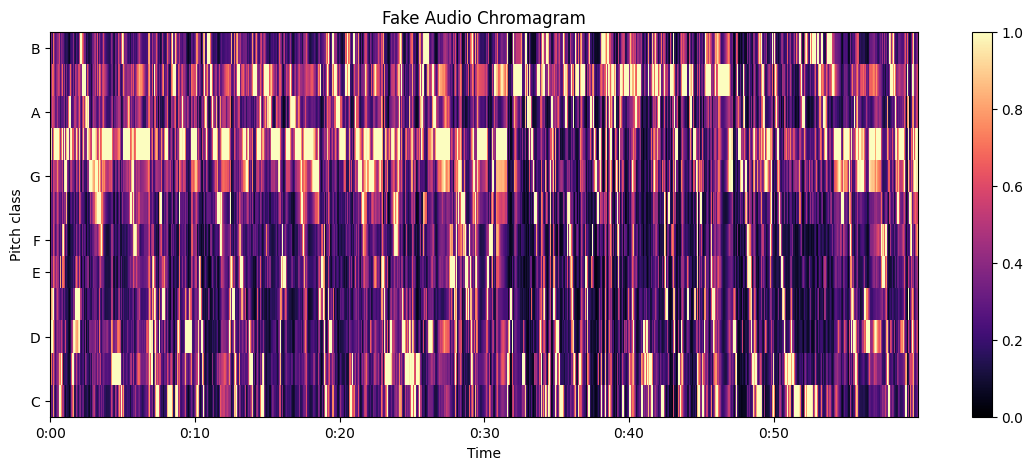

In [23]:
fake_chroma = librosa.feature.chroma_cqt(y = fake_ad, sr = fake_sr, bins_per_octave=36)
plt.figure(figsize=(14,5))
librosa.display.specshow(fake_chroma, sr = fake_sr, x_axis= 'time', y_axis = 'chroma', vmin = 0, vmax = 1)
plt.colorbar()
plt.title('Fake Audio Chromagram')
plt.show()

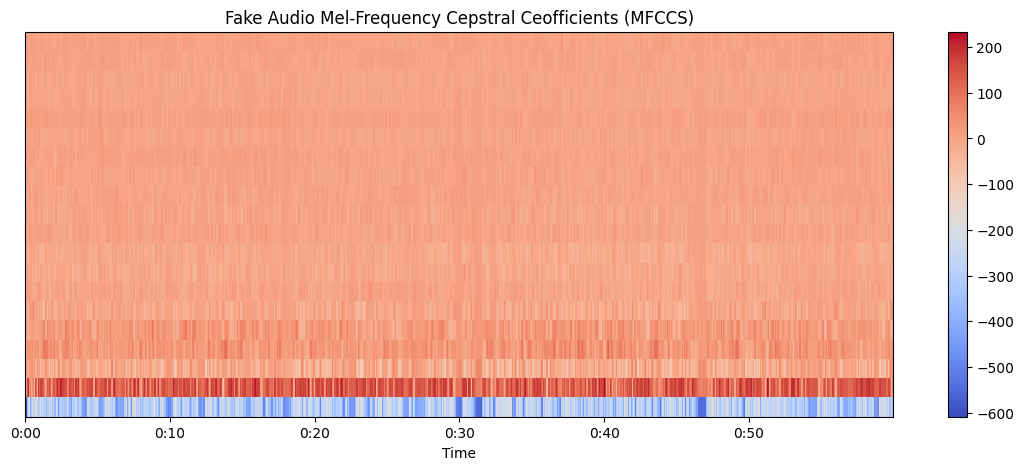

In [24]:
fake_mfcc = librosa.feature.mfcc(y = fake_ad, sr = fake_sr)
plt.figure(figsize = (14,5))
librosa.display.specshow(fake_mfcc, sr = fake_sr, x_axis ='time')
plt.colorbar()
plt.title('Fake Audio Mel-Frequency Cepstral Ceofficients (MFCCS)')
plt.show()

## 2. Feature Extraction & Preprocess

**Steps involved in this section:**
- Extracting Features from audio files using librosa
- Handling class imbalance by over-sampling the minority class
- Splitting the data between training and testing 

### 2.1 Feature Extraction using librosa

In [34]:
def extract_features(audio_path, max_length=500):
    features = []
    labels = []
    for folder in os.listdir(audio_path):
        folder_path = os.path.join(audio_path, folder)
        for file in tqdm(os.listdir(folder_path)):
            file_path = os.path.join(folder_path, file)
            try:
                # Load audio file
                audio, _ = librosa.load(file_path, sr=16000)
                # Extract features (example: using Mel-Frequency Cepstral Coefficients)
                mfccs = librosa.feature.mfcc(y=audio, sr=16000, n_mfcc=40)
                # Pad or trim the feature array to a fixed length
                if mfccs.shape[1] < max_length:
                    mfccs = np.pad(mfccs, ((0, 0), (0, max_length - mfccs.shape[1])), mode='constant')
                else:
                    mfccs = mfccs[:, :max_length]
                mfccs = (mfccs - np.mean(mfccs)) / (np.std(mfccs) + 1e-8)
                features.append(mfccs)
                # Assign label
                if folder == 'FAKE':
                    labels.append(1)  # 1 for fake
                else:
                    labels.append(0)  # 0 for real
            except Exception as e:
                print(f"Error encountered while parsing file: {file_path}")
                continue
    return np.array(features), np.array(labels)

# Example usage
audio_path = '/kaggle/input/deep-voice-deepfake-voice-recognition/KAGGLE/AUDIO'
x, y = extract_features(audio_path)

print("Features shape:", x.shape)
print("Labels shape:", y.shape)


100%|██████████| 8/8 [00:13<00:00,  1.64s/it]

Features shape: (64, 40, 500)
Labels shape: (64,)


### 2.2performing over-sampling to handle class imbalance

In [45]:
# 1. Flatten x from (64, 40, 500) to (64, 20000) for the oversampler
nsamples, nx, ny = x.shape
x_flat = x.reshape((nsamples, nx * ny))

# 2. Apply RandomOverSampler
ros = RandomOverSampler(random_state=42)
x_resampled_flat, y_resampled = ros.fit_resample(x_flat, y)

# 3. Reshape x back to (N, 40, 500)
x_resampled = x_resampled_flat.reshape((-1, nx, ny))

print("Resampled features shape:", x_resampled.shape)
print("Resampled labels shape:", y_resampled.shape)
print("New class distribution:", np.bincount(y_resampled))

Resampled features shape: (112, 40, 500)
Resampled labels shape: (112,)
New class distribution: [56 56]


### 2.3 Splitting the data for testing and training

In [46]:
xtrain, xtest, ytrain, ytest = train_test_split(
    x_resampled, y_resampled, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_resampled
)

# 3. Model Architecture & Training

**Steps involved in this section:**
- Creating a 2D Convolution Model for training
- Compiling the model by optimizers, loss function and performance metrics
- Fitting and training the model

In [47]:
model = Sequential([
    Reshape((40, 500, 1), input_shape=xtrain.shape[1:]),  # Reshape input to add channel dimension
    Conv2D(32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

/opt/conda/lib/python3.10/site-packages/keras/src/layers/reshaping/reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [50]:
model.compile(optimizer='adam', loss = 'binary_crossentropy', metrics  = ['accuracy', tf.keras.metrics.Precision()])

In [51]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=4, 
    restore_best_weights=True
)

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=2, 
    min_lr=1e-6, 
    verbose=1
)

# 5. Train cleanly without class_weight interference
history = model.fit(
    xtrain, ytrain, 
    validation_data=(xtest, ytest), 
    batch_size=32, 
    epochs=50, 
    shuffle=True,
    callbacks=[early_stopping, lr_scheduler]
)

Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 702ms/step - accuracy: 0.7761 - loss: 0.5328 - precision: 0.7108 - val_accuracy: 0.6522 - val_loss: 0.4719 - val_precision: 0.5882 - learning_rate: 0.0010
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 541ms/step - accuracy: 0.9480 - loss: 0.2847 - precision: 0.9098 - val_accuracy: 0.8696 - val_loss: 0.2818 - val_precision: 0.8333 - learning_rate: 0.0010
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 528ms/step - accuracy: 0.9810 - loss: 0.1579 - precision: 0.9808 - val_accuracy: 0.9565 - val_loss: 0.2278 - val_precision: 1.0000 - learning_rate: 0.0010
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 511ms/step - accuracy: 0.9888 - loss: 0.0993 - precision: 0.9787 - val_accuracy: 0.9565 - val_loss: 0.0891 - val_precision: 1.0000 - learning_rate: 0.0010
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 510ms/step - accuracy: 0.9944 - loss: 0.0489 - precision: 1.0000 - val_accuracy: 0.9565 - val_loss: 0.1162 - val_precision: 1.0000 - learning_rate: 0.0010
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━

## 4. Evaluation & Deployment Readiness

**Steps in this section:**
- evaluate the final model on test data
- pllotting the model training and validation accuracy and loss over epochs
- classification report and confusion matrix to show precision, recall and F1-score of the trained model
- Saving the model for integration with backend

In [52]:
loss,accuracy = model.evaluate(xtest,ytest)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.9565 - loss: 0.0704 - precision: 1.0000


ValueError: too many values to unpack (expected 2)

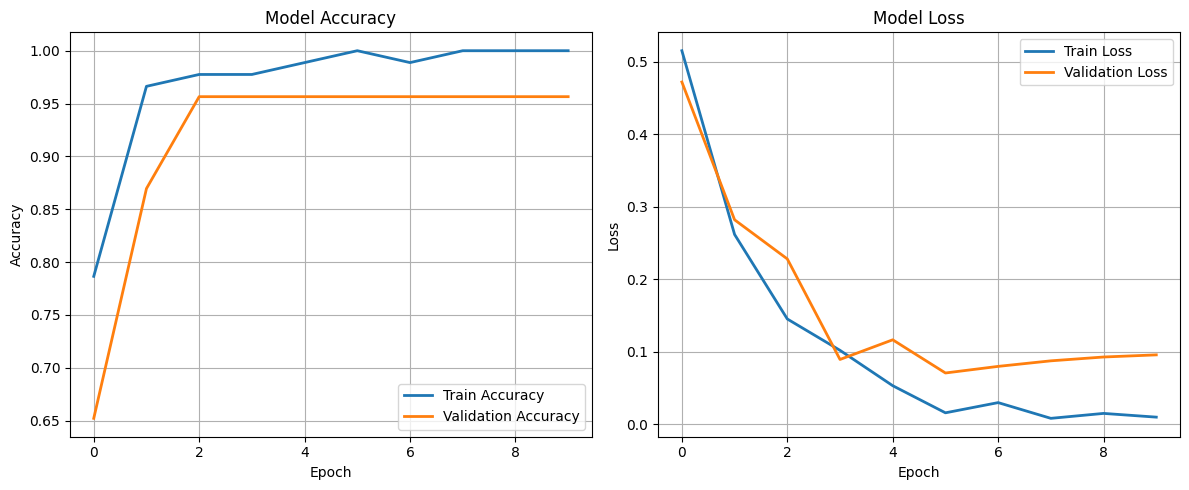

In [53]:
# 1. Plot Training and Validation Accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
if 'val_accuracy' in history.history:
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 2. Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', linewidth=2)
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [54]:
y_preds = model.predict(xtest)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step


Classification Report:
              precision    recall  f1-score   support

        REAL       0.92      1.00      0.96        12
        FAKE       1.00      0.91      0.95        11

    accuracy                           0.96        23
   macro avg       0.96      0.95      0.96        23
weighted avg       0.96      0.96      0.96        23



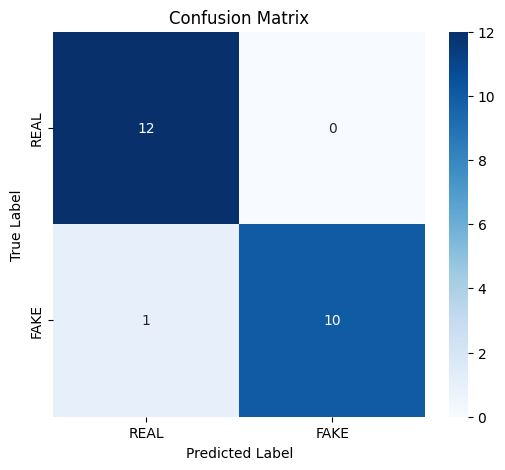

In [55]:
# Convert probability predictions to binary labels (0 or 1)
y_pred_classes = (y_preds > 0.5).astype(int)

# Generate confusion matrix
cm = confusion_matrix(ytest, y_pred_classes)

# Print classification report
print("Classification Report:")
print(classification_report(ytest, y_pred_classes, target_names=['REAL', 'FAKE']))

# Plot confusion matrix using seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['REAL', 'FAKE'], 
            yticklabels=['REAL', 'FAKE'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [56]:
model.save('deepfake_voice_model.keras')